In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

pd.set_option('display.max_columns',None)


In [6]:
df=pd.read_csv("glass.csv")

In [7]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [8]:
df.tail()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
209,1.51623,14.14,0.0,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.0,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.0,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.0,1.94,73.61,0.00,8.48,1.57,0.0,7
213,1.51711,14.23,0.0,2.08,73.36,0.00,8.62,1.67,0.0,7


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [10]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [11]:
df.isnull().sum()

,0
RI,0
Na,0
Mg,0
Al,0
Si,0
K,0
Ca,0
Ba,0
Fe,0
Type,0


In [13]:
df.columns

Index(['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type'], dtype='object')

In [14]:
df.duplicated().sum()

np.int64(1)

In [19]:
df["Type"].unique()

array([1, 2, 3, 5, 6, 7])

In [20]:
df["Type"].value_counts()

,count
Type,
2,76
1,70
7,29
3,17
5,13
6,9


In [22]:
df.drop_duplicates()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1
...,...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7


In [23]:
# Bar plot

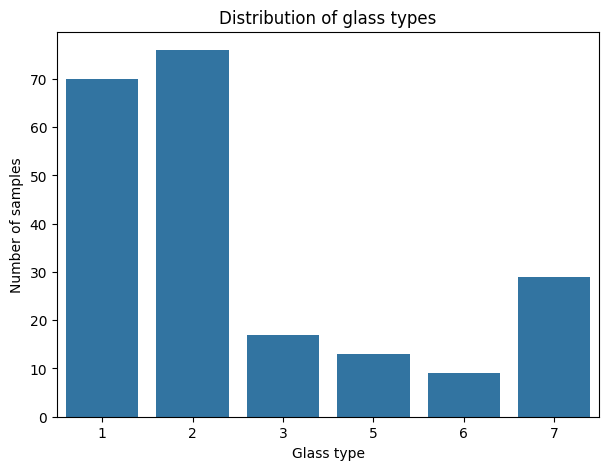

In [25]:
plt.figure(figsize=(7,5))
sns.countplot(data=df,x="Type")
plt.title("Distribution of glass types")
plt.xlabel("Glass type")
plt.ylabel("Number of samples")
plt.show()

In [26]:
# Pie chart

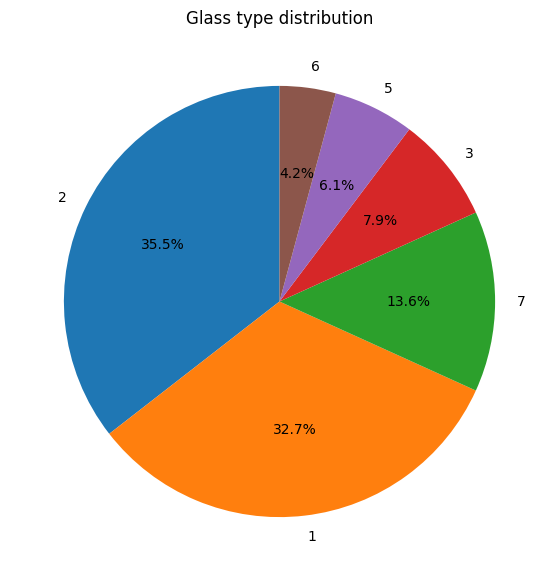

In [28]:
class_counts=df["Type"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(class_counts,labels=class_counts.index,autopct="%1.1f%%",startangle=90)
plt.title("Glass type distribution")
plt.show()

In [29]:
# Histograms

In [31]:
numerical_features=["RI","Na","Mg","Al","Si","K","Ca","Ba","Fe"]


AttributeError: module 'matplotlib.pyplot' has no attribute 'subtitle'

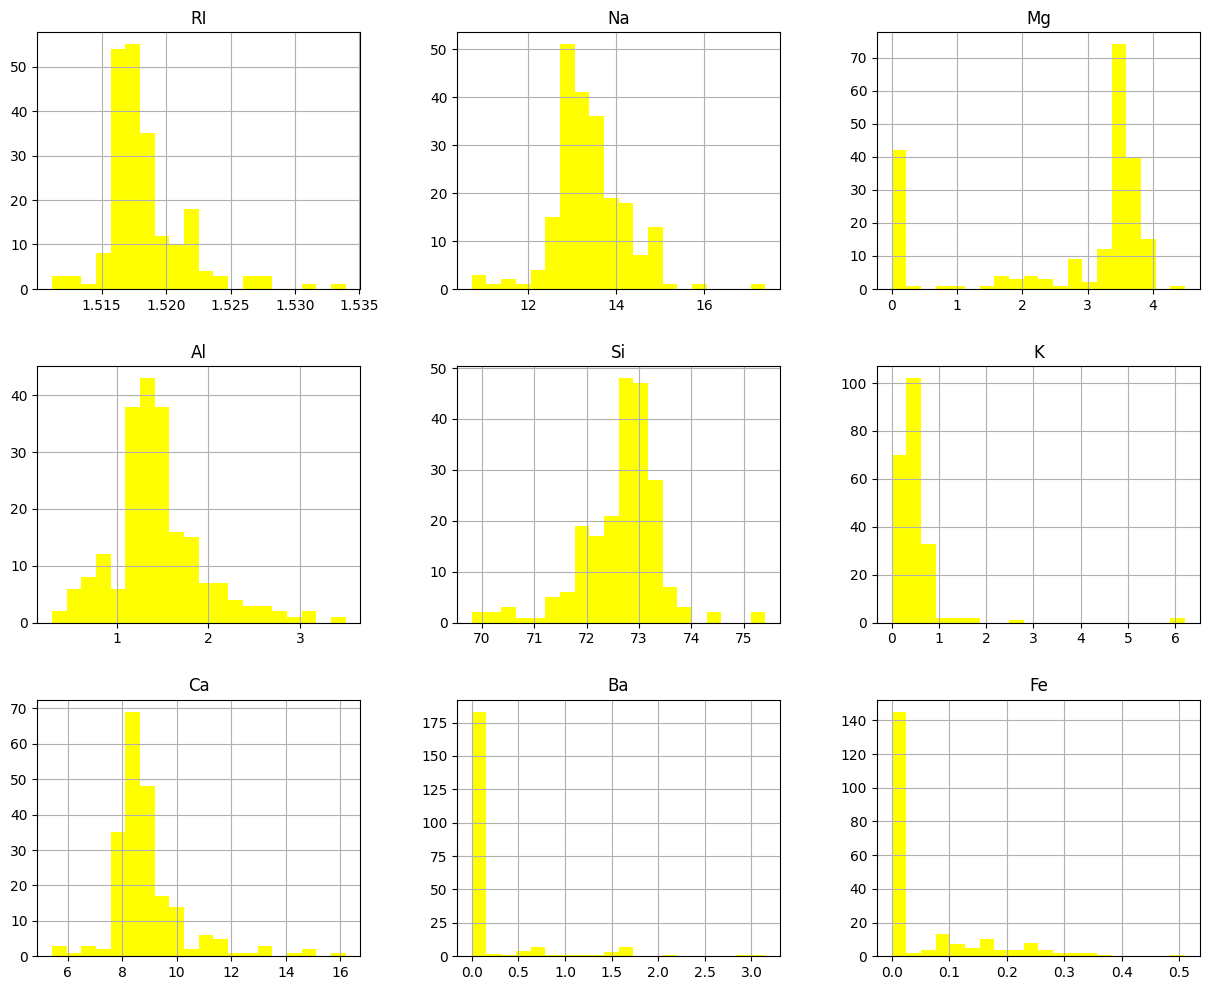

In [34]:
df[numerical_features].hist(figsize=(15,12),bins=20,color="yellow")
plt.subtitle("Distribution of numerical features",fontsize=16,)
plt.tight_layout()
plt.show()

In [36]:
# BOXPLOT

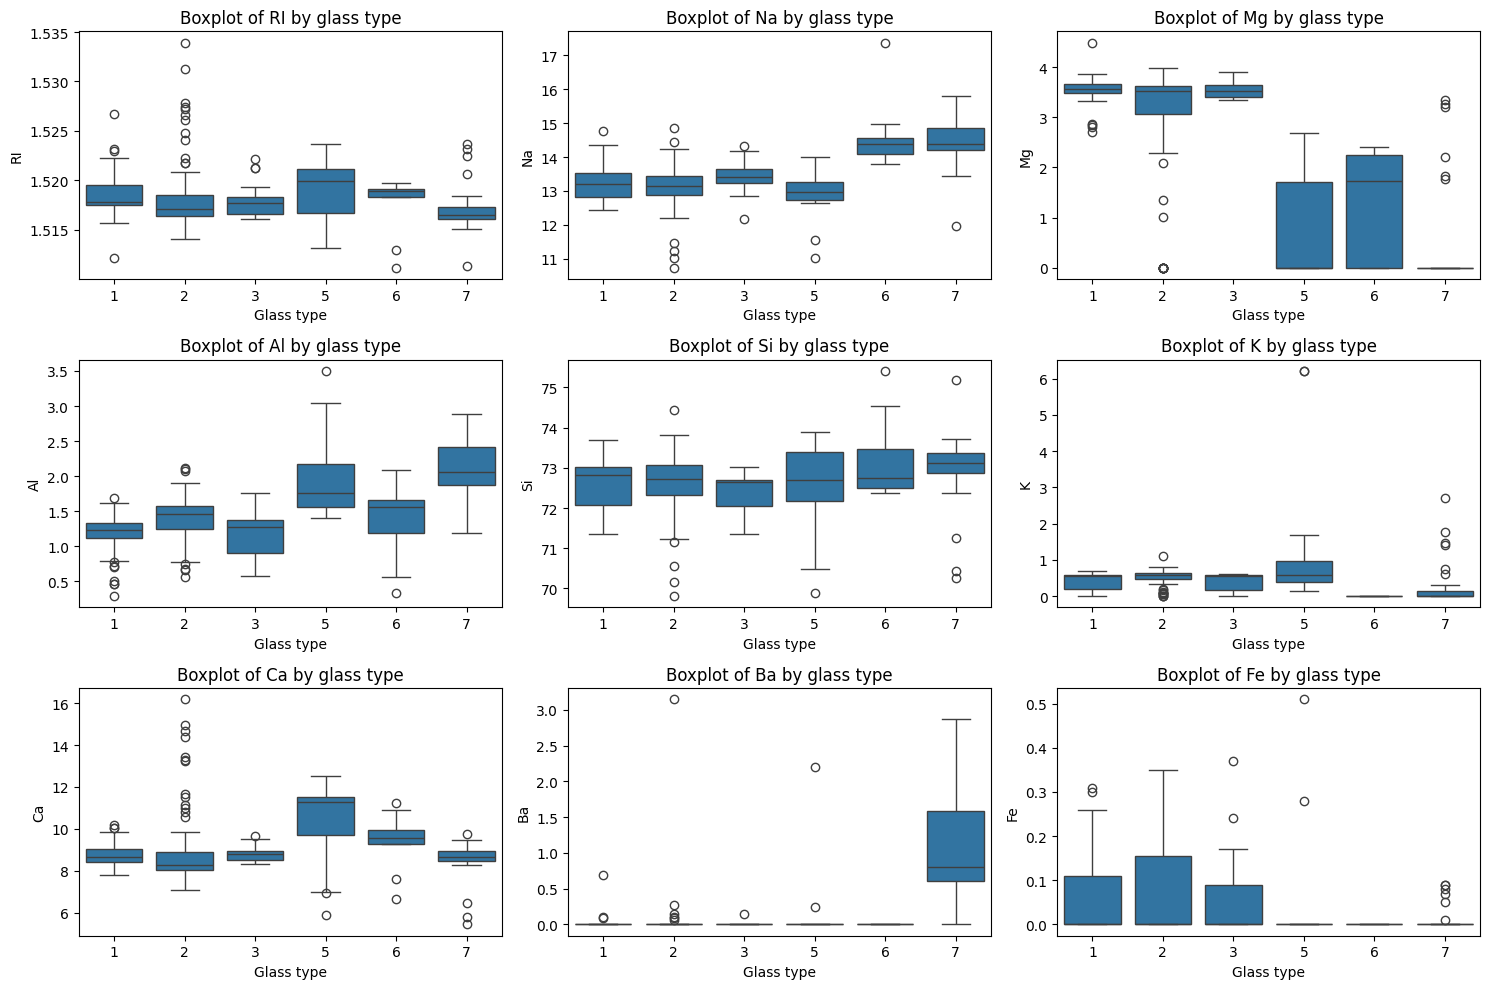

In [42]:
plt.figure(figsize=(15,10))
for i,column in enumerate(numerical_features):
    plt.subplot(3,3,i+1)
    sns.boxplot(data=df,x="Type",y=column)
    plt.title(f"Boxplot of {column} by glass type")
    plt.xlabel("Glass type")
    plt.ylabel(column)
plt.tight_layout()
plt.show()

In [37]:
# Histogram with kde function

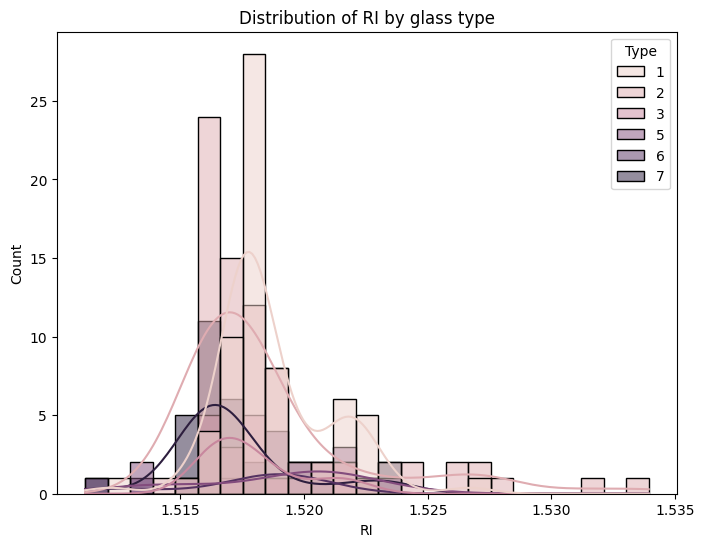

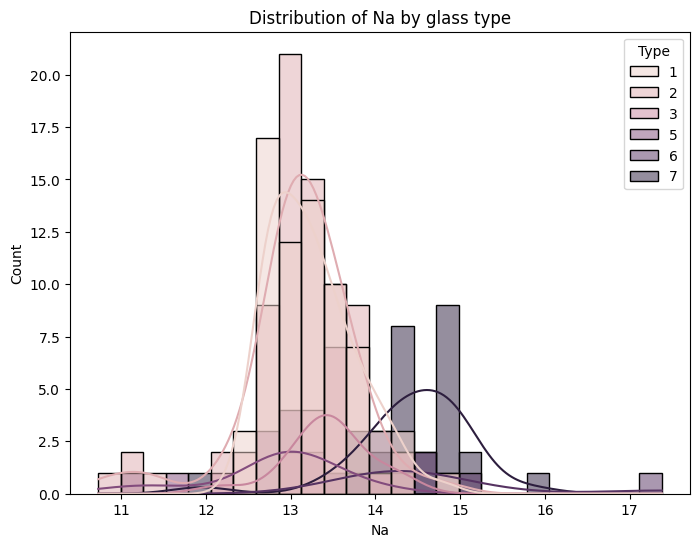

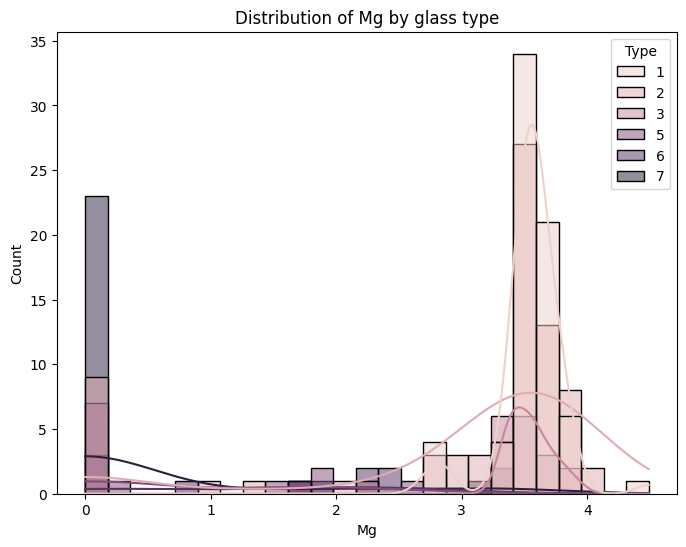

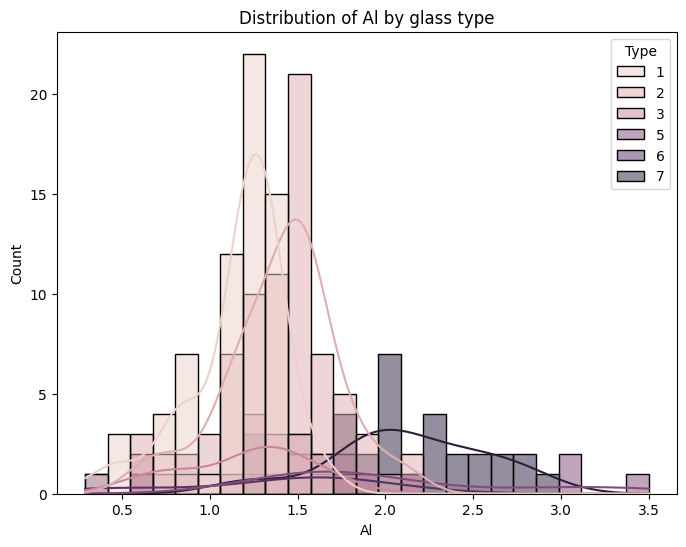

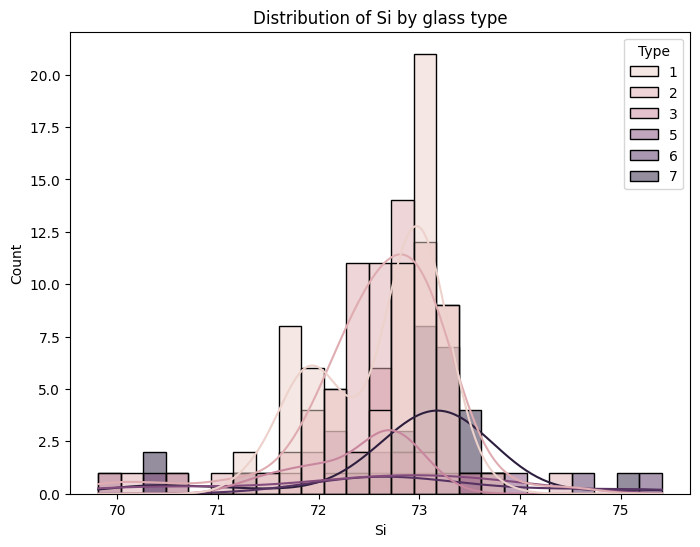

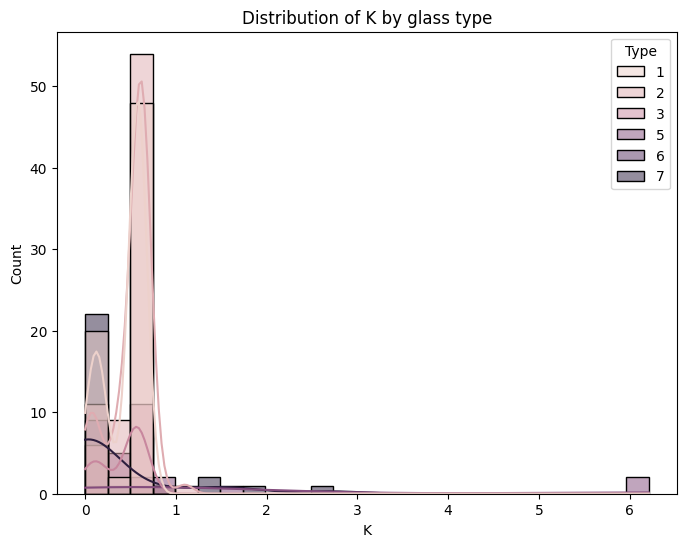

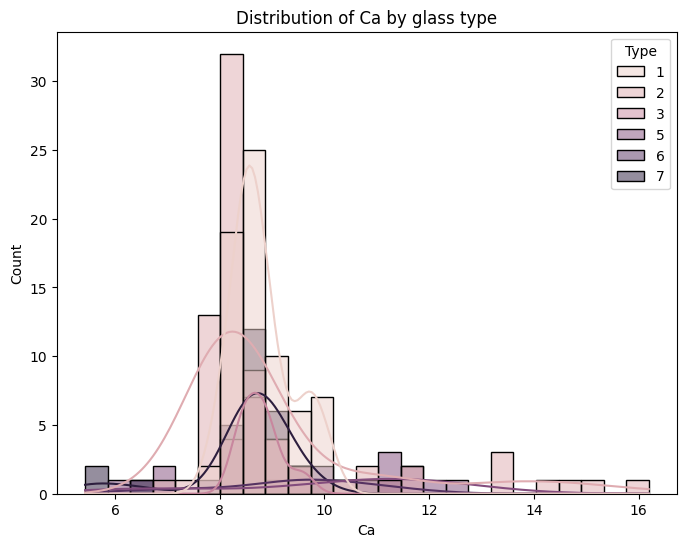

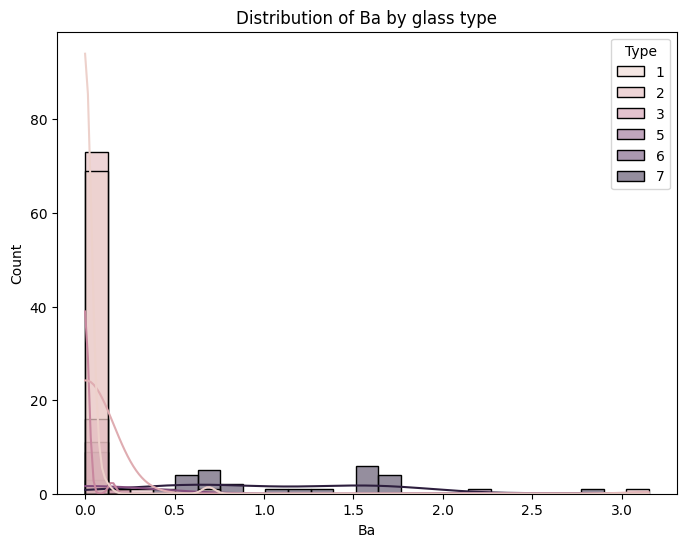

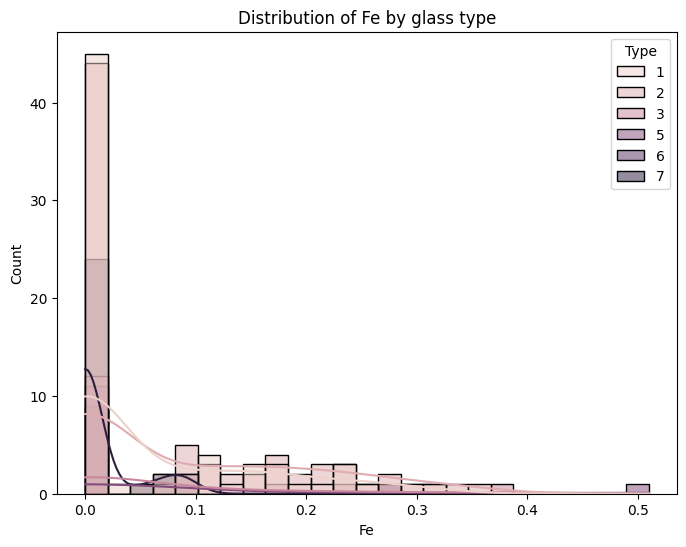

In [38]:
for column in numerical_features:
    plt.figure(figsize=(8,6))
    sns.histplot(data=df,x=column,hue="Type",kde=True,bins=25)
    plt.title(f"Distribution of {column} by glass type")
    plt.show()

In [39]:
# Correlation matrix

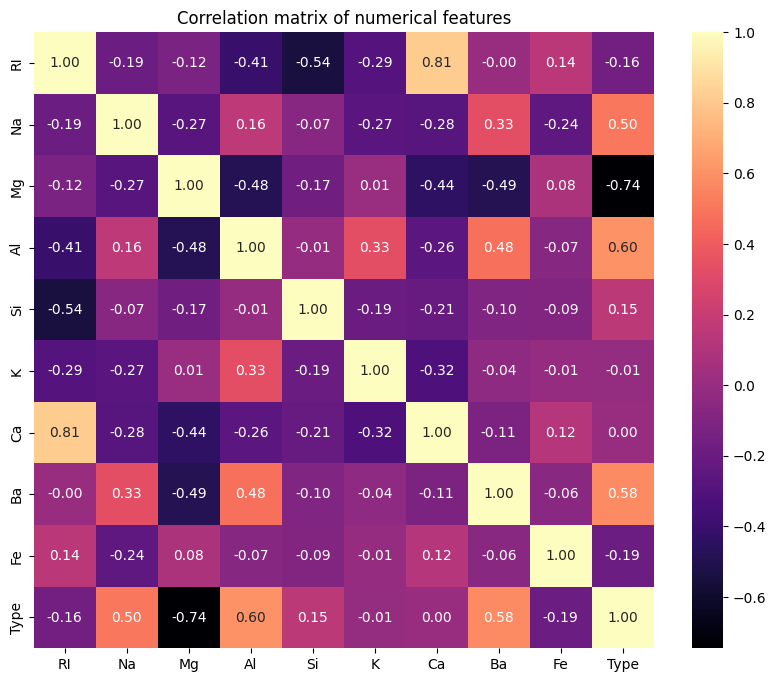

In [40]:
correlation_matrix=df.corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap="magma")
plt.title("Correlation matrix of numerical features")
plt.show()

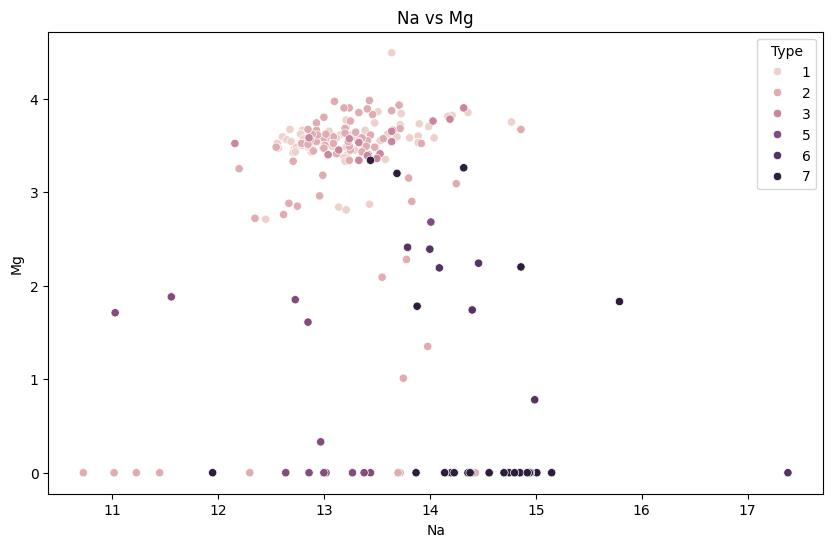

In [47]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x="Na",y="Mg",hue="Type")
plt.title("Na vs Mg")
plt.show()

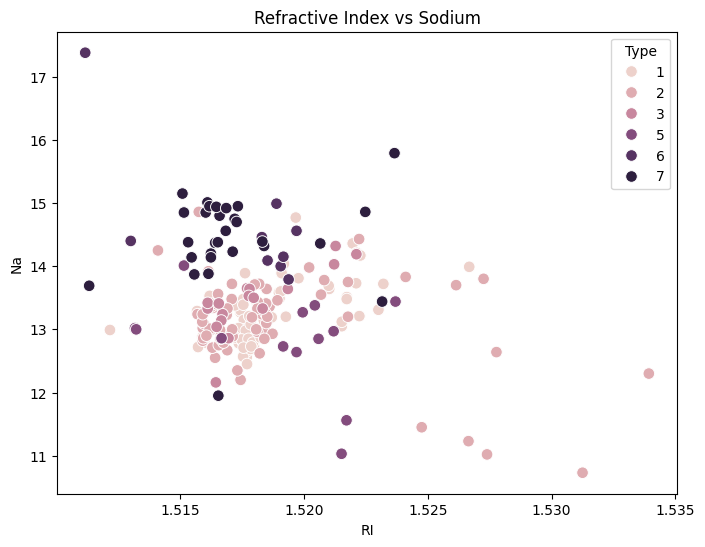

In [49]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="RI",
    y="Na",
    hue="Type",
    s=70
)

plt.title("Refractive Index vs Sodium")
plt.show()


In [50]:
# Data preprocessing

In [52]:
label_encoder=LabelEncoder()
df["Type_encoded"]=label_encoder.fit_transform(df["Type"])
print(df[["Type","Type_encoded"]].head(5))

   Type  Type_encoded
0     0             0
1     0             0
2     0             0
3     0             0
4     0             0


In [54]:
print("type mapping:")
for index ,type_name  in enumerate(label_encoder.classes_):
    print(index,"=",type_name)

type mapping:
0 = 0
1 = 1
2 = 2
3 = 3
4 = 4
5 = 5


In [56]:
X=df[numerical_features]
y=df["Type_encoded"]
print("x.shape:",X.shape)
print("y.shape:",y.shape)

x.shape: (214, 9)
y.shape: (214,)


In [58]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("X_train.shape:",X_train.shape)
print("X_test.shape:",X_test.shape)

X_train.shape: (171, 9)
X_test.shape: (43, 9)


In [59]:
GaussianNB()

GaussianNB()

In [60]:
gnb=GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [61]:
y_pred=gnb.predict(X_test)
print("Predicted types")
print(y_pred)

Predicted types
[0 5 0 5 0 3 0 0 0 0 4 1 0 0 4 1 5 2 2 4 1 5 5 5 0 1 0 0 1 0 1 0 2 0 0 5 3
 2 0 5 1 5 2]


In [65]:
comparision=pd.DataFrame({"Actual type":y_test,"Predicted type":y_pred})
print(comparision.head(5))

     Actual type  Predicted type
9              0               0
197            5               5
66             0               0
191            5               5
117            1               0


In [66]:
comparision["Actual Type"]=label_encoder.inverse_transform(comparision["Actual type"])
comparision["Predicted Type"]=label_encoder.inverse_transform(comparision["Predicted type"])
print(comparision.head(5))

     Actual type  Predicted type  Actual Type  Predicted Type
9              0               0            0               0
197            5               5            5               5
66             0               0            0               0
191            5               5            5               5
117            1               0            1               0


In [68]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
print("Accuracy(%):",accuracy*100)

Accuracy: 0.5581395348837209
Accuracy(%): 55.81395348837209


In [69]:
precision=precision_score(y_test,y_pred,average="weighted")
print("Precision:",precision)
print("Precision(%):",precision*100)

Precision: 0.5544307645538836
Precision(%): 55.443076455388365


In [70]:
recall=recall_score(y_test,y_pred,average="weighted")
print("Recall:",recall)
print("Recall(%):",recall*100)

Recall: 0.5581395348837209
Recall(%): 55.81395348837209


In [71]:
f1_score=f1_score(y_test,y_pred,average="weighted")
print("F1 score:",f1_score)
print("F1 score(%):",f1_score*100)

F1 score: 0.5316917464660282
F1 score(%): 53.169174646602826


In [72]:
print("===MODEL PERFORMANCE===")
print("Accuracy:",accuracy)
print("Precision:",precision)
print("Recall:",recall)
print("F1 score:",f1_score)


===MODEL PERFORMANCE===
Accuracy: 0.5581395348837209
Precision: 0.5544307645538836
Recall: 0.5581395348837209
F1 score: 0.5316917464660282


In [74]:

print("Classfification report:\n")
print(classification_report(y_test,y_pred))


Classfification report:

              precision    recall  f1-score   support

           0       0.41      0.64      0.50        11
           1       0.43      0.21      0.29        14
           2       0.40      0.67      0.50         3
           3       0.50      0.25      0.33         4
           4       1.00      1.00      1.00         3
           5       0.89      1.00      0.94         8

    accuracy                           0.56        43
   macro avg       0.60      0.63      0.59        43
weighted avg       0.55      0.56      0.53        43



In [75]:
cm=confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[7 1 3 0 0 0]
 [9 3 0 1 0 1]
 [1 0 2 0 0 0]
 [0 3 0 1 0 0]
 [0 0 0 0 3 0]
 [0 0 0 0 0 8]]


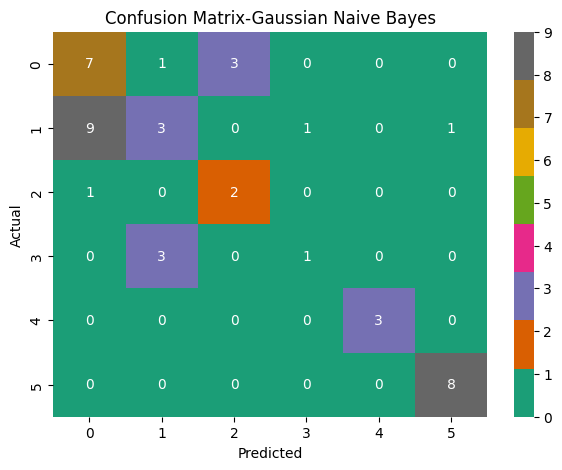

In [78]:
plt.figure(figsize=(7,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Dark2",xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix-Gaussian Naive Bayes")
plt.show()

In [80]:
from sklearn.metrics import accuracy_score
y_train_pred=gnb.predict(X_train)
y_test_pred=gnb.predict(X_test)
accuracy_train=accuracy_score(y_train,y_train_pred)
accuracy_test=accuracy_score(y_test,y_test_pred)
print("Training accuracy",accuracy_train)
print("Testing accuracy:",accuracy_test)

Training accuracy 0.5614035087719298
Testing accuracy: 0.5581395348837209


In [82]:
# Main hyperparameters

In [83]:
GaussianNB(var_smoothing=1e-9)

GaussianNB()

In [84]:
print(gnb.get_params())

{'priors': None, 'var_smoothing': 1e-09}


In [101]:
smoothing_values = [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]
results = []
for value in smoothing_values:
  model=GaussianNB(var_smoothing=value)
  model.fit(X_train, y_train)
  prediction = model.predict(X_test)
  accuracy = accuracy_score(y_test, prediction)
  precision = precision_score(y_test, prediction, average='weighted')
  recall = recall_score(y_test, prediction, average='weighted')
  f1_value = f1_score(y_test, prediction, average='weighted')
  results.append((value, accuracy, precision, recall, f1_value))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [102]:
new_sample_data = {}

print("Please enter values for the following features:")
new_sample_data['RI'] = float(input("Enter Refractive Index (RI): "))
new_sample_data['Na'] = float(input("Enter Sodium (Na): "))
new_sample_data['Mg'] = float(input("Enter Magnesium (Mg): "))
new_sample_data['Al'] = float(input("Enter Aluminum (Al): "))
new_sample_data['Si'] = float(input("Enter Silicon (Si): "))
new_sample_data['K'] = float(input("Enter Potassium (K): "))
new_sample_data['Ca'] = float(input("Enter Calcium (Ca): "))
new_sample_data['Ba'] = float(input("Enter Barium (Ba): "))
new_sample_data['Fe'] = float(input("Enter Iron (Fe): "))

new_sample = pd.DataFrame([new_sample_data])

predicted_type_encoded = gnb.predict(new_sample)
predicted_type_original = label_encoder.inverse_transform(predicted_type_encoded)

print(f"\nPredicted Glass Type: {predicted_type_original[0]}")

Please enter values for the following features:
Enter Refractive Index (RI): 10
Enter Sodium (Na): 21
Enter Magnesium (Mg): 48
Enter Aluminum (Al): 12
Enter Silicon (Si): 66
Enter Potassium (K): 7
Enter Calcium (Ca): 30
Enter Barium (Ba): 10
Enter Iron (Fe): 45

Predicted Glass Type: 1
